<a href="https://colab.research.google.com/github/LiliiaKuchvara/Python-DTA/blob/main/%D0%97%D0%B0%D0%BD%D1%8F%D1%82%D1%82%D1%8F_5_%D0%92%D1%96%D0%B4%D0%B1%D1%96%D1%80_%D0%BE%D0%B7%D0%BD%D0%B0%D0%BA_%D1%8F%D0%BA_%D0%BF%D0%BE%D0%B7%D0%B1%D1%83%D1%82%D0%B8%D1%81%D1%8F_%D0%B7%D0%B0%D0%B9%D0%B2%D0%BE%D0%B3%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Заняття 5. Відбір ознак: як позбутися зайвого

**Блок 2. Дані як основа ML**

## 1. Навіщо відбирати ознаки

| Причина | Пояснення |
|---|---|
| **Шум** | випадкові ознаки модель може «запам'ятати» як закономірність — і помилятися на нових даних |
| **Пояснюваність** | модель з 8 ознаками легше пояснити бізнесу, ніж модель з 80 |
| **Вартість даних** | кожну ознаку треба збирати, зберігати, перевіряти щодня |
| **Витоки й дублікати** | їх треба прибрати незалежно від якості моделі |

### Три групи методів

1. **Ручні перевірки (здоровий глузд):** константи, ідентифікатори, дублікати, витоки.
2. **Фільтри (статистика):** кореляція з ціллю, `SelectKBest` — оцінка кожної ознаки окремо.
3. **Модельні:** модель сама вирішує, що важливо (`Lasso` обнуляє непотрібні коефіцієнти,
   дерева рахують важливість).

**Головне правило:** відбір теж «вчиться» на даних, тому робимо його **лише на train** і
перевіряємо результат на test.

## 2. Демонстрація: прогноз прогресування діабету

Набір `load_diabetes` з `scikit-learn`: 442 пацієнти, 10 медичних показників (вік, індекс маси
тіла, тиск, 6 аналізів крові); ціль — показник прогресування хвороби через рік.

Щоб показати проблему шуму, додамо 40 **випадкових** колонок, які ніяк не пов'язані з ціллю, —
так буває, коли в датасет «про всяк випадок» додають усе підряд.

In [1]:
# Підготовка: бібліотеки та функція завантаження даних (працює в Colab і локально)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
DATA_URL = "https://raw.githubusercontent.com/KsiuTretyakova/ml_for_analys_dta_2026/refs/heads/main/data/"


def load_csv(name):
    """Читає CSV з поточної теки, з теки data/, з DATA_URL або просить завантажити файл у Colab."""
    for path in (name, os.path.join("data", name)):
        if os.path.exists(path):
            return pd.read_csv(path)
    if DATA_URL:
        return pd.read_csv(DATA_URL.rstrip("/") + "/" + name)
    from google.colab import files
    print(f"Натисніть «Choose files» і виберіть файл {name}")
    files.upload()
    return pd.read_csv(name)

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.metrics import mean_absolute_error

diab = load_diabetes(as_frame=True)
X = diab.data.copy()
rng = np.random.default_rng(42)
for i in range(40):
    X[f"noise_{i}"] = rng.normal(scale=0.0476, size=len(X))  # той самий масштаб, що й у справжніх ознак
y = diab.target
print(X.shape)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)

(442, 50)


### Крок 1. Модель на всіх ознаках

In [3]:
def test_mae(cols):
    m = LinearRegression().fit(X_tr[cols], y_tr)
    return mean_absolute_error(y_te, m.predict(X_te[cols]))

all_cols = list(X.columns)
real_cols = list(diab.data.columns)
print(f"Усі 50 ознак:        MAE = {test_mae(all_cols):.1f}")
print(f"Лише 10 справжніх:   MAE = {test_mae(real_cols):.1f}")

Усі 50 ознак:        MAE = 45.7
Лише 10 справжніх:   MAE = 41.9


Шумові колонки погіршили прогноз: модель «підлаштувалася» під випадкові збіги в train.
У реальності ми не знаємо, які колонки шумові. Подивимося, чи знайдуть їх методи відбору.

### Крок 2. Кореляція з ціллю (на train)

In [4]:
corr = X_tr.corrwith(y_tr).abs().sort_values(ascending=False)
corr.head(12).round(3)

,0
bmi,0.605
s5,0.523
bp,0.447
s4,0.430
s3,0.402
s6,0.383
age,0.191
s1,0.187
s2,0.159
noise_10,0.151


Справжні показники (`bmi`, `s5`, `bp`, ...) — нагорі, але деякі шумові колонки теж мають
кореляцію 0.1–0.15 через випадковість. Кореляція дивиться на кожну ознаку окремо і лише на лінійний
зв'язок — це швидкий, але грубий фільтр.

### Крок 3. SelectKBest — залишити k найкращих

In [5]:
from sklearn.feature_selection import SelectKBest, f_regression

for k in [3, 5, 8, 10, 15, 30, 50]:
    selector = SelectKBest(f_regression, k=k).fit(X_tr, y_tr)
    cols = list(X_tr.columns[selector.get_support()])
    noise_in = sum(c.startswith("noise") for c in cols)
    print(f"k={k:2d}: MAE = {test_mae(cols):.1f}, шумових серед обраних: {noise_in}")

k= 3: MAE = 43.3, шумових серед обраних: 0
k= 5: MAE = 42.9, шумових серед обраних: 0
k= 8: MAE = 42.7, шумових серед обраних: 0
k=10: MAE = 42.7, шумових серед обраних: 1
k=15: MAE = 43.2, шумових серед обраних: 6
k=30: MAE = 44.6, шумових серед обраних: 21
k=50: MAE = 45.7, шумових серед обраних: 40


Зверніть увагу: **найкраще k обираємо не за test**, інакше test перестає бути чесною перевіркою.
Правильний спосіб — крос-валідація на train (заняття 10). Тут test використовуємо лише для
демонстрації, як k впливає на якість.

### Крок 4. Lasso — модель, яка сама обнуляє зайве

`Lasso` — лінійна регресія зі «штрафом» за великі коефіцієнти. Непотрібні ознаки отримують
коефіцієнт рівно 0. `LassoCV` сам підбирає силу штрафу на train.

In [6]:
lasso = LassoCV(cv=5, random_state=42).fit(X_tr, y_tr)
coef = pd.Series(lasso.coef_, index=X.columns)
kept = list(coef[coef != 0].index)
print("Lasso залишив:", kept)
print(f"MAE моделі Lasso: {mean_absolute_error(y_te, lasso.predict(X_te)):.1f}")
print(f"MAE звичайної регресії на ознаках, які залишив Lasso: {test_mae(kept):.1f}")

Lasso залишив: ['sex', 'bmi', 'bp', 's3', 's5', 'noise_3', 'noise_15', 'noise_22', 'noise_32', 'noise_33']
MAE моделі Lasso: 42.2
MAE звичайної регресії на ознаках, які залишив Lasso: 43.8


Lasso відкинув більшість шумових колонок, і якість майже як у моделі на справжніх ознаках. Але кілька
шумових ознак лишилися з малим коефіцієнтом, а деякі справжні він відкинув —
жоден автоматичний метод не ідеальний, тому фінальне рішення поєднує метод і здоровий глузд.

### Крок 5. Мультиколінеарність: ознаки-«близнюки»

Якщо дві ознаки майже однакові (наприклад, пробіг у км і в милях), лінійна модель не може
вирішити, якій з них «віддати» вплив: коефіцієнти стають нестабільними й незрозумілими. Шукаємо
пари з кореляцією > 0.9 і лишаємо одну з пари.

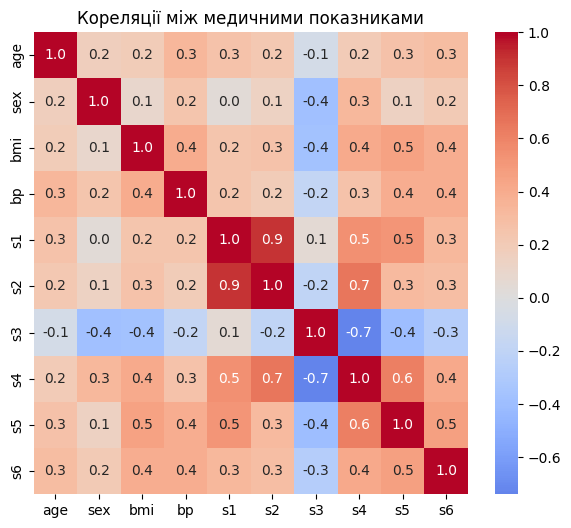

In [7]:
import seaborn as sns

plt.figure(figsize=(7, 6))
sns.heatmap(diab.data.corr().round(2), annot=True, cmap="coolwarm", center=0, fmt=".1f")
plt.title("Кореляції між медичними показниками")
plt.show()

`s1` і `s2` (два показники холестерину) корелюють приблизно на 0.9 — це «близнюки». Для прогнозу
це не критично, але коефіцієнти такої пари не варто пояснювати бізнесу окремо.

---
## 3. Практика: ціна вживаного авто

Сайт оголошень хоче підказувати продавцям ринкову ціну авто (`price_usd`). Датасет зібрали з
усього, що є в базі оголошень, — у ньому є зайве.

### Завдання 1. Ручні перевірки

Завантажте `used_cars.csv`. Знайдіть і поясніть у коментарях:
1. колонки-константи (`nunique() == 1`);
2. ідентифікатори;
3. дублікати інших колонок (кореляція > 0.99);
4. витік цілі.

Видаліть їх і запишіть список колонок, що лишилися.

In [8]:
cars = load_csv("used_cars.csv")
# currency - константа; car_id - ідентифікатор; mileage_miles - той самий пробіг;
# price_uah - та сама ціна в гривнях (витік цілі)
# Ваш код тут

# Завантажуємо датасет із GitHub
cars = load_csv("used_cars.csv")

# Перевіряємо розмір
print("Розмір:", cars.shape)

# 1. Колонки-константи
constant_cols = [
    col for col in cars.columns
    if cars[col].nunique(dropna=False) == 1
]
print("Константи:", constant_cols)

# 2. Ідентифікатори
id_cols = ["car_id"]

# 3. Перевіряємо кореляції
numeric = cars.select_dtypes(include="number")
corr = numeric.corr().abs()

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if corr.iloc[i, j] > 0.99:
            print(
                corr.columns[i],
                "<->",
                corr.columns[j],
                round(corr.iloc[i, j], 4)
            )

# 4. Видаляємо зайві колонки
# mileage_miles — дублює mileage_km
# price_uah — витік цілі (ціна в іншій валюті)

drop_cols = constant_cols + id_cols + [
    "mileage_miles",
    "price_uah"
]

cars_clean = cars.drop(columns=drop_cols)

# 5. Виводимо результат
print("\nВидалені колонки:", drop_cols)
print("\nКолонки, що залишилися:")
print(cars_clean.columns.tolist())

print("\nРозмір очищеного датасету:", cars_clean.shape)


Розмір: (6000, 18)
Константи: ['currency']
mileage_km <-> mileage_miles 1.0
price_uah <-> price_usd 1.0

Видалені колонки: ['currency', 'car_id', 'mileage_miles', 'price_uah']

Колонки, що залишилися:
['brand', 'year', 'mileage_km', 'engine_l', 'fuel', 'transmission', 'body_type', 'owners', 'accident_history', 'color', 'region', 'listing_views', 'photo_count', 'price_usd']

Розмір очищеного датасету: (6000, 14)


### Завдання 2. Базова модель на всіх ознаках

1. Розділіть на train/test (25 %, `random_state=42`).
2. Зберіть `Pipeline`: `OneHotEncoder(handle_unknown="ignore")` для текстових колонок, числові —
   без змін (`"passthrough"`), модель `LinearRegression`.
3. Порахуйте MAE на тесті в доларах.

In [10]:
# Ваш код тут


# 1. Імпортуємо необхідні бібліотеки

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


# 2. Завантажуємо дані
# Якщо cars_clean вже створений у попередньому завданні,
# використовуємо його. Інакше завантажуємо та очищуємо датасет.

try:
    cars_clean
except NameError:
    cars = load_csv("used_cars.csv")

    # Видаляємо константи
    constant_cols = [
        col for col in cars.columns
        if cars[col].nunique(dropna=False) == 1
    ]

    # Видаляємо ідентифікатори, дублікати та витік цілі
    drop_cols = constant_cols + [
        "car_id",
        "mileage_miles",
        "price_uah"
    ]

    cars_clean = cars.drop(
        columns=[col for col in drop_cols if col in cars.columns]
    )


# 3. Відокремлюємо ознаки від цільової змінної

X = cars_clean.drop(columns=["price_usd"])
y = cars_clean["price_usd"]


# 4. Розділяємо дані на навчальну та тестову вибірки
# 75% — train, 25% — test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)


# 5. Визначаємо текстові та числові колонки

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

print("\nТекстові колонки:", categorical_cols)
print("\nЧислові колонки:", numeric_cols)


# 6. Створюємо обробку ознак
# Текстові колонки кодуємо через OneHotEncoder
# Числові колонки залишаємо без змін (passthrough)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "num",
            "passthrough",
            numeric_cols
        )
    ]
)


# 7. Створюємо Pipeline
# Спочатку обробка ознак, потім лінійна регресія

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])


# 8. Навчаємо модель на train

model.fit(X_train, y_train)

print("\nМодель успішно навчена!")


# 9. Робимо прогноз на тестовій вибірці

y_pred = model.predict(X_test)


# 10. Розраховуємо MAE
# MAE показує середню абсолютну помилку прогнозу в доларах

mae = mean_absolute_error(y_test, y_pred)

print("\n================================")
print(f"MAE базової моделі: {mae:.2f} USD")
print("================================")


# 11. Порівнюємо реальні та прогнозовані ціни

results = pd.DataFrame({
    "Реальна ціна (USD)": y_test.values,
    "Прогнозована ціна (USD)": y_pred
})

results["Абсолютна помилка"] = abs(
    results["Реальна ціна (USD)"] -
    results["Прогнозована ціна (USD)"]
)

print("\nПриклад прогнозів:")
display(results.head(10))


# 12. Додаткова інформація про модель

print("\nКІНЦЕВИЙ РЕЗУЛЬТАТ")
print("Кількість ознак:", X.shape[1])
print("Кількість автомобілів для навчання:", len(X_train))
print("Кількість автомобілів для тестування:", len(X_test))
print(f"Середня помилка прогнозу: {mae:.2f} доларів")


Розмір навчальної вибірки: (4500, 13)
Розмір тестової вибірки: (1500, 13)

Текстові колонки: ['brand', 'fuel', 'transmission', 'body_type', 'color', 'region']

Числові колонки: ['year', 'mileage_km', 'engine_l', 'owners', 'accident_history', 'listing_views', 'photo_count']

Модель успішно навчена!

MAE базової моделі: 1462.01 USD

Приклад прогнозів:


,Реальна ціна (USD),Прогнозована ціна (USD),Абсолютна помилка
0,4160.0,5776.118177,1616.118177
1,13170.0,10862.392662,2307.607338
2,3790.0,4868.629928,1078.629928
3,3990.0,5915.546271,1925.546271
4,1930.0,2246.967401,316.967401
5,8060.0,9302.597338,1242.597338
6,6970.0,8590.222015,1620.222015
7,6180.0,7806.040203,1626.040203
8,5540.0,7681.492222,2141.492222
9,3390.0,2695.562434,694.437566



КІНЦЕВИЙ РЕЗУЛЬТАТ
Кількість ознак: 13
Кількість автомобілів для навчання: 4500
Кількість автомобілів для тестування: 1500
Середня помилка прогнозу: 1462.01 доларів


### Завдання 3. Кореляції та підозрілі ознаки

1. Порахуйте кореляцію числових ознак з ціною **на train**. Які ознаки майже не пов'язані з ціною?
2. Подивіться на середню ціну за `color` і `region` (`groupby`). Чи відрізняються вони суттєво?

КОРЕЛЯЦІЯ ЧИСЛОВИХ ОЗНАК З ЦІНОЮ:
year                0.851
engine_l            0.059
listing_views       0.019
photo_count        -0.006
accident_history   -0.081
owners             -0.547
mileage_km         -0.773
Name: price_usd, dtype: float64

ОЗНАКИ З МАЙЖЕ ВІДСУТНЬОЮ КОРЕЛЯЦІЄЮ:
engine_l            0.059
listing_views       0.019
photo_count        -0.006
accident_history   -0.081
Name: price_usd, dtype: float64


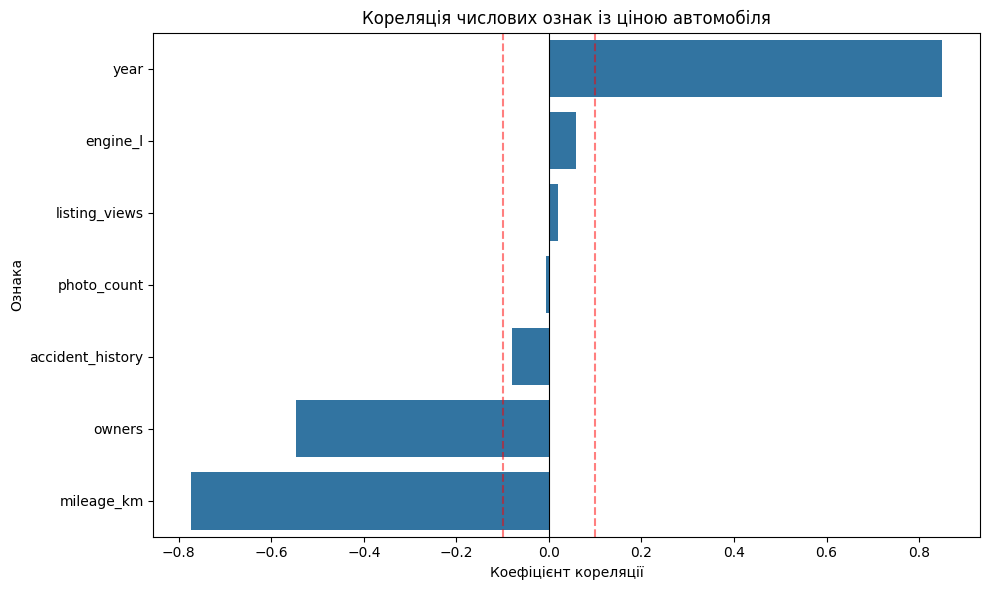


СЕРЕДНЯ ЦІНА ЗА КОЛЬОРОМ:
           mean  median  count
color                         
black   6081.09  4520.0    780
blue    6040.05  4570.0    798
white   5824.24  4480.0    733
red     5728.20  4160.0    718
grey    5709.46  4090.0    718
silver  5620.13  3920.0    753


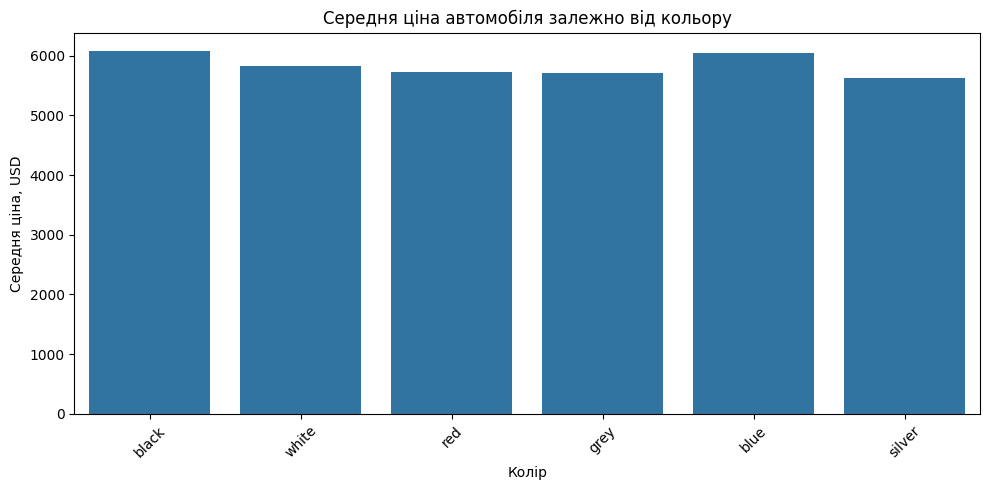


СЕРЕДНЯ ЦІНА ЗА РЕГІОНОМ:
            mean  median  count
region                         
Kyiv     6032.60  4530.0    810
Lviv     5923.51  4380.0    718
Odesa    5876.62  4390.0    751
Dnipro   5830.21  4195.0    722
Kharkiv  5815.81  4365.0    742
Other    5546.91  4000.0    757


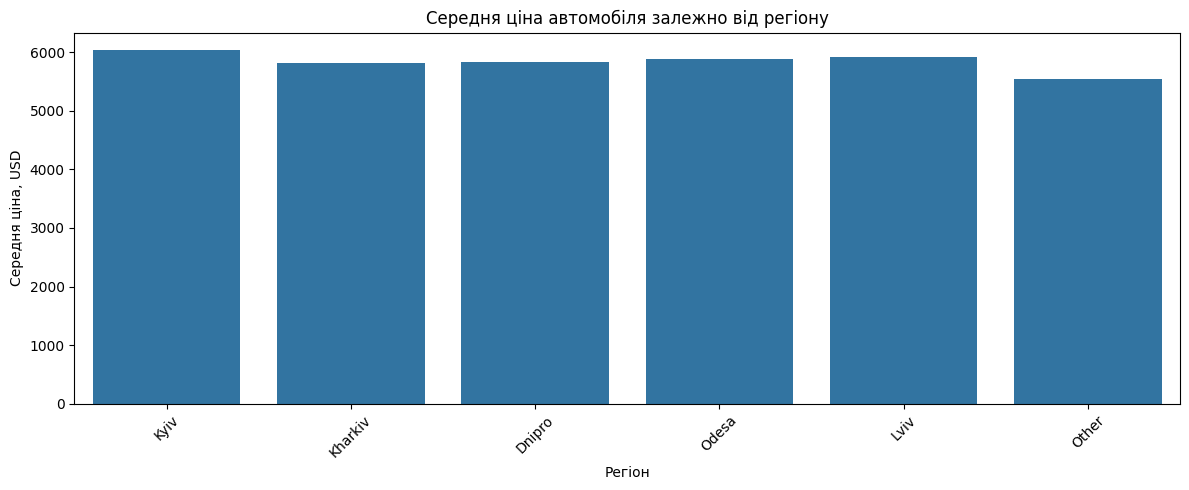


ПІДСУМКИ ЗАВДАННЯ 3

Ознаки з майже нульовою кореляцією:
- engine_l: 0.059
- listing_views: 0.019
- photo_count: -0.006
- accident_history: -0.081

Найдорожчий колір:
black
Найдешевший колір:
silver

Найдорожчий регіон:
Kyiv
Найдешевший регіон:
Other

Різниця між середніми цінами за кольором: 460.96 USD
Різниця між середніми цінами за регіоном: 485.7 USD


In [11]:
# listing_views, photo_count майже не корелюють з ціною; колір і регіон майже не змінюють середню ціну.
# Ваш код тут


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split


# 1. Підготовка даних

# Використовуємо очищений датасет із попередніх завдань
X = cars_clean.drop(columns=["price_usd"])
y = cars_clean["price_usd"]

# Розділяємо дані на train і test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# Об'єднуємо навчальні ознаки та ціну для аналізу
train_data = X_train.copy()
train_data["price_usd"] = y_train


# ============================================
# 2. КОРЕЛЯЦІЯ ЧИСЛОВИХ ОЗНАК З ЦІНОЮ
# ============================================

# Вибираємо тільки числові колонки
numeric_data = train_data.select_dtypes(include="number")

# Рахуємо кореляцію з ціною
correlations = (
    numeric_data.corr()["price_usd"]
    .drop("price_usd")
    .sort_values(ascending=False)
)

print("КОРЕЛЯЦІЯ ЧИСЛОВИХ ОЗНАК З ЦІНОЮ:")
print(correlations.round(3))


# Визначаємо ознаки з дуже слабкою кореляцією
weak_features = correlations[
    correlations.abs() < 0.1
]

print("\nОЗНАКИ З МАЙЖЕ ВІДСУТНЬОЮ КОРЕЛЯЦІЄЮ:")
print(weak_features.round(3))


# Візуалізація кореляцій
plt.figure(figsize=(10, 6))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(0.1, color="red", linestyle="--", alpha=0.5)
plt.axvline(-0.1, color="red", linestyle="--", alpha=0.5)

plt.title("Кореляція числових ознак із ціною автомобіля")
plt.xlabel("Коефіцієнт кореляції")
plt.ylabel("Ознака")

plt.tight_layout()
plt.show()


# ============================================
# 3. СЕРЕДНЯ ЦІНА ЗА КОЛЬОРОМ АВТОМОБІЛЯ
# ============================================

price_by_color = (
    train_data.groupby("color")["price_usd"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

print("\nСЕРЕДНЯ ЦІНА ЗА КОЛЬОРОМ:")
print(price_by_color.round(2))


# Графік середньої ціни за кольором
plt.figure(figsize=(10, 5))

sns.barplot(
    data=train_data,
    x="color",
    y="price_usd",
    errorbar=None
)

plt.title("Середня ціна автомобіля залежно від кольору")
plt.xlabel("Колір")
plt.ylabel("Середня ціна, USD")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================
# 4. СЕРЕДНЯ ЦІНА ЗА РЕГІОНОМ
# ============================================

price_by_region = (
    train_data.groupby("region")["price_usd"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

print("\nСЕРЕДНЯ ЦІНА ЗА РЕГІОНОМ:")
print(price_by_region.round(2))


# Графік середньої ціни за регіоном
plt.figure(figsize=(12, 5))

sns.barplot(
    data=train_data,
    x="region",
    y="price_usd",
    errorbar=None
)

plt.title("Середня ціна автомобіля залежно від регіону")
plt.xlabel("Регіон")
plt.ylabel("Середня ціна, USD")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================
# 5. ПІДСУМКИ АНАЛІЗУ
# ============================================

print("\n====================================")
print("ПІДСУМКИ ЗАВДАННЯ 3")
print("====================================")

print("\nОзнаки з майже нульовою кореляцією:")
if len(weak_features) > 0:
    for feature, value in weak_features.items():
        print(f"- {feature}: {value:.3f}")
else:
    print("Таких ознак не знайдено.")

print("\nНайдорожчий колір:")
print(price_by_color["mean"].idxmax())

print("Найдешевший колір:")
print(price_by_color["mean"].idxmin())

print("\nНайдорожчий регіон:")
print(price_by_region["mean"].idxmax())

print("Найдешевший регіон:")
print(price_by_region["mean"].idxmin())

print("\nРізниця між середніми цінами за кольором:",
      round(price_by_color["mean"].max() -
            price_by_color["mean"].min(), 2), "USD")

print("Різниця між середніми цінами за регіоном:",
      round(price_by_region["mean"].max() -
            price_by_region["mean"].min(), 2), "USD")


### Завдання 4. Модель без зайвого

Приберіть ознаки, які у завданні 3 виявилися непов'язаними з ціною, і навчіть ту саму модель.
Порівняйте MAE. Що виграв бізнес, навіть якщо MAE змінилась мало?

In [13]:
# Якість майже та сама, але модель простіша: продавцю не треба вводити колір і регіон,
# а пояснювати ціну легше.
# Ваш код тут


import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


# 1. Підготовка даних

X = cars_clean.drop(columns=["price_usd"])
y = cars_clean["price_usd"]


# 2. Розділяємо дані на train і test

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)


# 3. Модель №1 — використовуємо всі ознаки

def create_model(X_data):

    categorical_cols = X_data.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    numeric_cols = X_data.select_dtypes(
        include="number"
    ).columns.tolist()

    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             categorical_cols),
            ("num", "passthrough", numeric_cols)
        ]
    )

    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])


# Навчаємо модель на всіх ознаках

model_all = create_model(X_train)

model_all.fit(X_train, y_train)

pred_all = model_all.predict(X_test)

mae_all = mean_absolute_error(y_test, pred_all)


# 4. Модель №2 — без color та region

# Видаляємо колір і регіон
remove_cols = ["color", "region"]

X_train_simple = X_train.drop(columns=remove_cols)
X_test_simple = X_test.drop(columns=remove_cols)

# Створюємо та навчаємо спрощену модель

model_simple = create_model(X_train_simple)

model_simple.fit(X_train_simple, y_train)

pred_simple = model_simple.predict(X_test_simple)

mae_simple = mean_absolute_error(y_test, pred_simple)


# 5. Порівнюємо результати

print("======================================")
print("ПОРІВНЯННЯ МОДЕЛЕЙ")
print("======================================")

print(f"MAE моделі з усіма ознаками: {mae_all:.2f} USD")
print(f"MAE моделі без color і region: {mae_simple:.2f} USD")

print("\nРізниця MAE:", round(mae_simple - mae_all, 2), "USD")


# 6. Порівняльна таблиця

comparison = pd.DataFrame({
    "Модель": [
        "Усі ознаки",
        "Без color та region"
    ],
    "Кількість ознак": [
        X_train.shape[1],
        X_train_simple.shape[1]
    ],
    "MAE (USD)": [
        mae_all,
        mae_simple
    ]
})

display(comparison.round(2))


# 7. Показуємо, які ознаки залишилися

print("\nВидалені ознаки:", remove_cols)

print("\nОзнаки спрощеної моделі:")
print(X_train_simple.columns.tolist())

print("\nКількість ознак до спрощення:", X_train.shape[1])
print("Кількість ознак після спрощення:", X_train_simple.shape[1])


# 8. Висновок

if abs(mae_simple - mae_all) < 100:
    print("\nЯкість моделей майже однакова.")
    print("Спрощена модель потребує менше даних від продавця.")
else:
    print("\nЯкість моделей відрізняється.")
    print("Потрібно оцінити, чи виправдане спрощення.")


ПОРІВНЯННЯ МОДЕЛЕЙ
MAE моделі з усіма ознаками: 1462.01 USD
MAE моделі без color і region: 1458.41 USD

Різниця MAE: -3.6 USD


,Модель,Кількість ознак,MAE (USD)
0,Усі ознаки,13,1462.01
1,Без color та region,11,1458.41



Видалені ознаки: ['color', 'region']

Ознаки спрощеної моделі:
['brand', 'year', 'mileage_km', 'engine_l', 'fuel', 'transmission', 'body_type', 'owners', 'accident_history', 'listing_views', 'photo_count']

Кількість ознак до спрощення: 13
Кількість ознак після спрощення: 11

Якість моделей майже однакова.
Спрощена модель потребує менше даних від продавця.


### Завдання 5. Перевірте себе Lasso

Навчіть `LassoCV(cv=5, random_state=42)` на всіх ознаках після one-hot кодування
(числові ознаки перед цим масштабуйте `StandardScaler`, бо штраф Lasso залежить від масштабу).
Які ознаки Lasso обнулив? Чи збігається це з вашим ручним відбором?

In [15]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LassoCV


# 1. Підготовка даних

X = cars_clean.drop(columns=["price_usd"])
y = cars_clean["price_usd"]


# 2. Розділяємо дані на train і test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Розмір train:", X_train.shape)
print("Розмір test:", X_test.shape)


# 3. Визначаємо текстові та числові ознаки

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

print("\nТекстові ознаки:", categorical_cols)
print("Числові ознаки:", numeric_cols)


# 4. Створюємо обробку ознак
# Текстові ознаки кодуємо через OneHotEncoder
# Числові масштабуємо через StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "num",
            StandardScaler(),
            numeric_cols
        )
    ]
)


# 5. Створюємо Pipeline з LassoCV
# cv=5 означає п'ятиблокову крос-валідацію

lasso_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "lasso",
        LassoCV(
            cv=5,
            random_state=42,
            max_iter=100000
        )
    )
])


# 6. Навчаємо модель тільки на train

lasso_model.fit(X_train, y_train)

print("\nМодель LassoCV успішно навчена!")


# 7. Отримуємо коефіцієнти моделі

lasso = lasso_model.named_steps["lasso"]

feature_names = (
    lasso_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = pd.Series(
    lasso.coef_,
    index=feature_names
)


# 8. Знаходимо ознаки, які Lasso обнулив

zero_features = coefficients[
    coefficients == 0
]

nonzero_features = coefficients[
    coefficients != 0
]

print("\n======================================")
print("РЕЗУЛЬТАТИ LASSO")
print("======================================")

print("\nКількість усіх ознак після One-Hot Encoding:",
      len(coefficients))

print("Кількість обнулених коефіцієнтів:",
      len(zero_features))

print("Кількість коефіцієнтів, що залишилися:",
      len(nonzero_features))

print("\nОЗНАКИ З НУЛЬОВИМИ КОЕФІЦІЄНТАМИ:")
print(zero_features.index.tolist())

print("\nОЗНАКИ З НЕНУЛЬОВИМИ КОЕФІЦІЄНТАМИ:")
print(nonzero_features.sort_values(
    key=abs,
    ascending=False
).round(3))


# 9. Аналізуємо результат на рівні початкових колонок
# Для текстових ознак перевіряємо всі створені категорії.
# Ознака повністю обнулена, якщо всі її коефіцієнти дорівнюють нулю.

encoder = (
    lasso_model.named_steps["preprocessor"]
    .named_transformers_["cat"]
)

encoded_names = encoder.get_feature_names_out(categorical_cols)

numeric_coefficients = coefficients[
    [f"num__{col}" for col in numeric_cols]
]

feature_summary = []

# Аналіз текстових колонок
start = 0

for col, categories in zip(
    categorical_cols,
    encoder.categories_
):
    count = len(categories)

    names = [
        f"cat__{name}"
        for name in encoded_names[start:start + count]
    ]

    values = coefficients[names]

    feature_summary.append({
        "Початкова ознака": col,
        "Кількість коефіцієнтів": count,
        "Ненульових": int((values != 0).sum()),
        "Повністю обнулена": bool((values == 0).all())
    })

    start += count


# Аналіз числових колонок
for col in numeric_cols:

    value = numeric_coefficients[f"num__{col}"]

    feature_summary.append({
        "Початкова ознака": col,
        "Кількість коефіцієнтів": 1,
        "Ненульових": int(value != 0),
        "Повністю обнулена": bool(value == 0)
    })


summary = pd.DataFrame(feature_summary)

print("\n======================================")
print("АНАЛІЗ ПОЧАТКОВИХ ОЗНАК")
print("======================================")

display(summary)


# 10. Показуємо параметр регуляризації

print("\nОптимальний alpha:", round(lasso.alpha_, 4))


# 11. Порівнюємо з ручним відбором
# У попередньому завданні ми прибирали color і region.
# Тут перевіряємо, чи Lasso також повністю їх обнулив.

print("\n======================================")
print("ПОРІВНЯННЯ З РУЧНИМ ВІДБОРОМ")
print("======================================")

manual_removed = ["color", "region"]

for col in manual_removed:

    row = summary[
        summary["Початкова ознака"] == col
    ]

    if len(row) > 0:
        is_zero = row["Повністю обнулена"].iloc[0]

        if is_zero:
            print(f"{col}: Lasso також повністю обнулив цю ознаку.")
        else:
            print(f"{col}: Lasso залишив частину коефіцієнтів.")

# Перевіряємо, чи є ознаки, які Lasso повністю обнулив
fully_removed = summary[
    summary["Повністю обнулена"]
]["Початкова ознака"].tolist()

print("\nОзнаки, які Lasso повністю обнулив:")
print(fully_removed)


Розмір train: (4500, 13)
Розмір test: (1500, 13)

Текстові ознаки: ['brand', 'fuel', 'transmission', 'body_type', 'color', 'region']
Числові ознаки: ['year', 'mileage_km', 'engine_l', 'owners', 'accident_history', 'listing_views', 'photo_count']

Модель LassoCV успішно навчена!

РЕЗУЛЬТАТИ LASSO

Кількість усіх ознак після One-Hot Encoding: 38
Кількість обнулених коефіцієнтів: 15
Кількість коефіцієнтів, що залишилися: 23

ОЗНАКИ З НУЛЬОВИМИ КОЕФІЦІЄНТАМИ:
['cat__brand_Skoda', 'cat__fuel_petrol', 'cat__transmission_manual', 'cat__body_type_hatchback', 'cat__body_type_minivan', 'cat__body_type_sedan', 'cat__color_black', 'cat__color_blue', 'cat__color_grey', 'cat__color_silver', 'cat__region_Kharkiv', 'cat__region_Lviv', 'cat__region_Odesa', 'cat__region_Other', 'num__photo_count']

ОЗНАКИ З НЕНУЛЬОВИМИ КОЕФІЦІЄНТАМИ:
num__year                      3097.429
cat__brand_BMW                 3027.391
cat__fuel_electric             1651.686
cat__brand_Toyota              1235.291
cat__fuel_hy

,Початкова ознака,Кількість коефіцієнтів,Ненульових,Повністю обнулена
0,brand,7,6,False
1,fuel,5,4,False
2,transmission,2,1,False
3,body_type,5,2,False
4,color,6,2,False
5,region,6,2,False
6,year,1,1,False
7,mileage_km,1,1,False
8,engine_l,1,1,False
9,owners,1,1,False



Оптимальний alpha: 7.3919

ПОРІВНЯННЯ З РУЧНИМ ВІДБОРОМ
color: Lasso залишив частину коефіцієнтів.
region: Lasso залишив частину коефіцієнтів.

Ознаки, які Lasso повністю обнулив:
['photo_count']


---
## Підсумок

- Спершу **ручні перевірки**: константи, ідентифікатори, дублікати, витоки.
- Потім **фільтри** (кореляція, `SelectKBest`) і **модельні методи** (`Lasso`).
- Відбір робимо на train; рішення перевіряємо на test (а найкраще — крос-валідацією).
- Простіша модель з тією самою якістю — це виграш для бізнесу.